In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
# url = "https://github.com/devidrees/PW-Data-Analytics-July-2026/blob/main/Projects/Global%20Music%20Streaming%20Project/Global_Music_Streaming_Listener_Preferences.csv"

# df = pd.read_csv(url, on_bad_lines="skip")
# df.head()

In [17]:
url = "/content/drive/MyDrive/Global_Music_Streaming_Listener_Preferences.csv"

df = pd.read_csv(url)

In [20]:
df.head(2)

,User_ID,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%)
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74
1,U1001,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25


In [4]:
# inspect data
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User_ID                                   5000 non-null   object 
 1   Age                                       5000 non-null   int64  
 2   Country                                   5000 non-null   object 
 3   Streaming Platform                        5000 non-null   object 
 4   Top Genre                                 5000 non-null   object 
 5   Minutes Streamed Per Day                  5000 non-null   int64  
 6   Number of Songs Liked                     5000 non-null   int64  
 7   Most Played Artist                        5000 non-null   object 
 8   Subscription Type                         5000 non-null   object 
 9   Listening Time (Morning/Afternoon/Night)  5000 non-null   object 
 10  Discover Weekly Engagement (%)      

,Age,Minutes Streamed Per Day,Number of Songs Liked,Discover Weekly Engagement (%),Repeat Song Rate (%)
count,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,36.664000,309.237200,253.51720,50.296464,42.391060
std,13.763844,172.029822,146.36928,23.171936,21.444121
min,13.000000,10.000000,1.00000,10.020000,5.000000
25%,25.000000,161.000000,126.00000,30.147500,24.195000
50%,37.000000,316.000000,254.00000,50.420000,41.960000
75%,49.000000,457.250000,382.00000,70.337500,60.740000
max,60.000000,600.000000,500.00000,89.990000,79.990000


In [5]:
# Check for null values
df.isnull().sum()

# check duplicates
df.duplicated().sum()

np.int64(0)

### Data Cleaning
- Learn [Data Imputation](https://www.geeksforgeeks.org/machine-learning/what-is-data-imputation)

### Data Visualization and Analysis
- you can do this in powerBI too

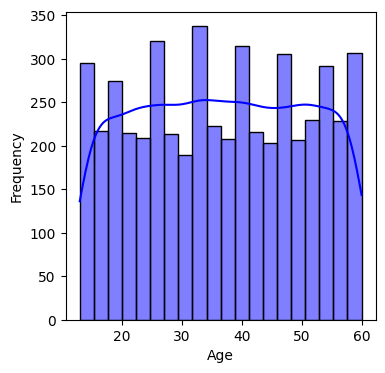

In [6]:
plt.figure(figsize=(4,4)) #

sns.histplot(df["Age"], # univariate
             bins=20, kde=True, color="blue")

plt.xlabel("Age")
plt.ylabel("Frequency")

# plt.title("Distribution of User Ages")
plt.show()

### most popular streaming platforms

In [25]:
df["Streaming Platform"].value_counts().index

Index(['Amazon Music', 'Tidal', 'Deezer', 'Spotify', 'YouTube', 'Apple Music'], dtype='object', name='Streaming Platform')

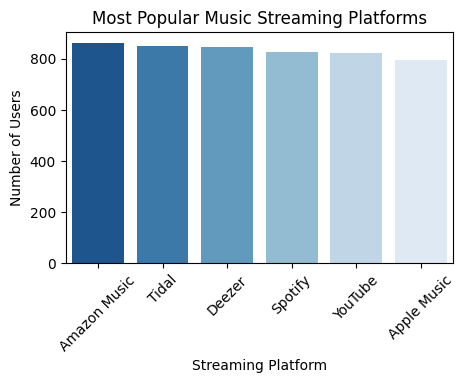

In [27]:
plt.figure(figsize=(5,3))

sns.countplot(
    x = df["Streaming Platform"],
    order = df["Streaming Platform"].value_counts().index,
    palette = 'Blues_r' )

plt.xlabel("Streaming Platform")
plt.ylabel("Number of Users")
plt.title("Most Popular Music Streaming Platforms")

plt.xticks(rotation=45)
plt.show()

### Listening Time Preference

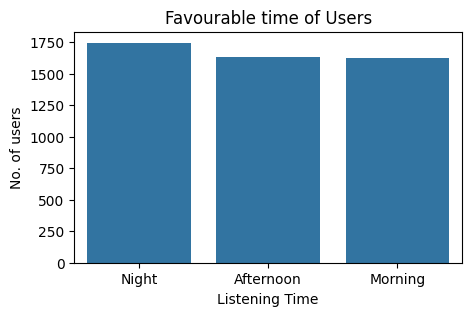

In [28]:
plt.figure(figsize=(5,3))
sns.countplot(x=df['Listening Time (Morning/Afternoon/Night)'], order=df['Listening Time (Morning/Afternoon/Night)'].value_counts().index)
plt.xlabel("Listening Time")
plt.ylabel("No. of users")
plt.title("Favourable time of Users")
plt.show()

### Top 10 Most streamed artists


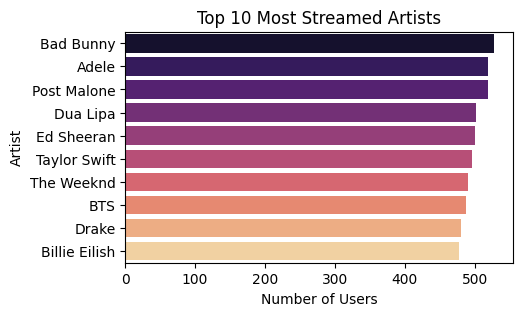

In [10]:
plt.figure(figsize=(5,3))
sns.countplot(y= df["Most Played Artist"], order= df["Most Played Artist"].value_counts().index, palette="magma")
plt.xlabel("Number of Users")
plt.ylabel("Artist")
plt.title("Top 10 Most Streamed Artists")
plt.show()

### Preffered Subscription Type by Age Groups
-

In [29]:
df.head()

,User_ID,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%)
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74
1,U1001,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25
2,U1002,49,Germany,Deezer,Pop,363,368,Post Malone,Premium,Afternoon,47.19,67.38
3,U1003,55,Australia,YouTube,Reggae,348,349,Dua Lipa,Premium,Morning,31.27,76.51
4,U1004,13,Germany,Amazon Music,Reggae,30,328,Adele,Free,Night,30.68,43.41


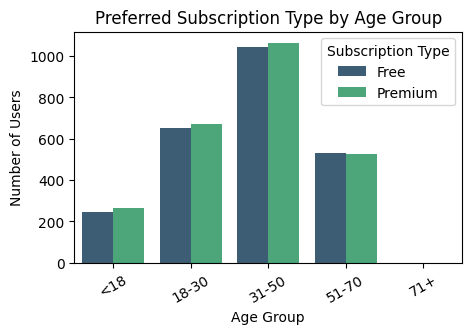

In [35]:
# we have to Bin age feature
bins = [0, 17, 30, 50, 70, float('inf')]
labels = ['<18', '18-30', '31-50', '51-70', '71+']
df['Age Group'] = pd.cut(df['Age'], bins = bins, labels= labels)

plt.figure(figsize=(5,3))
sns.countplot(data= df, x="Age Group", hue = "Subscription Type", palette=["#345e7d", "#3db579"])
plt.xlabel("Age Group")
plt.ylabel("Number of Users")
plt.title("Preferred Subscription Type by Age Group")
plt.xticks(rotation=30)
plt.show()

## Regional Trends in Music
- Countries -
- Top Genres that people listen to
- type of the music

In [37]:
df.head(1)

,User_ID,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%),Age Group
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74,31-50


In [39]:
df["Country"].value_counts().values

df["Top Genre"].value_counts()

,count
Top Genre,
Reggae,532
Jazz,532
EDM,528
Rock,516
R&B,495
Metal,491
Hip-Hop,485
Country,484
Classical,475


In [70]:
df.head()

,User_ID,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%),Age Group
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74,31-50
1,U1001,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25,18-30
2,U1002,49,Germany,Deezer,Pop,363,368,Post Malone,Premium,Afternoon,47.19,67.38,31-50
3,U1003,55,Australia,YouTube,Reggae,348,349,Dua Lipa,Premium,Morning,31.27,76.51,51-70
4,U1004,13,Germany,Amazon Music,Reggae,30,328,Adele,Free,Night,30.68,43.41,<18


In [55]:
top_genre_country = (
    df.groupby(['Country', 'Top Genre'])
    .size()
    .reset_index(name= "Count")
    .sort_values(['Country','Count'], ascending = [True, False])
)

In [ ]:
top_genre = (
    top_genre_country.groupby('Country')
    .first() # first entry -
    .reset_index()
    .sort_values('Count', ascending = False)
)

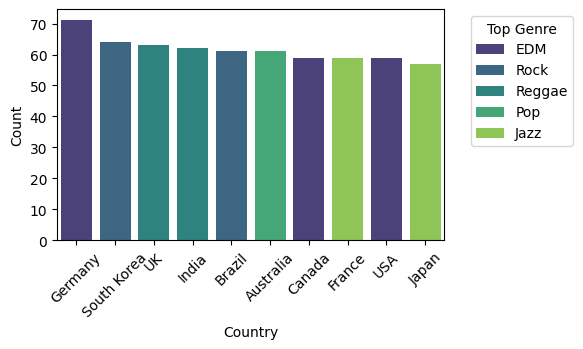

In [75]:
plt.figure(figsize=(5,3))
sns.barplot(
    data = top_genre,
    x = 'Country',
    y = 'Count',
    hue = 'Top Genre',
    palette='viridis'
    )

plt.legend(title='Top Genre', bbox_to_anchor=(1.05, 1), loc='upper left')


plt.xticks(rotation = 45)
plt.show()

<Axes: xlabel='Count', ylabel='Country'>

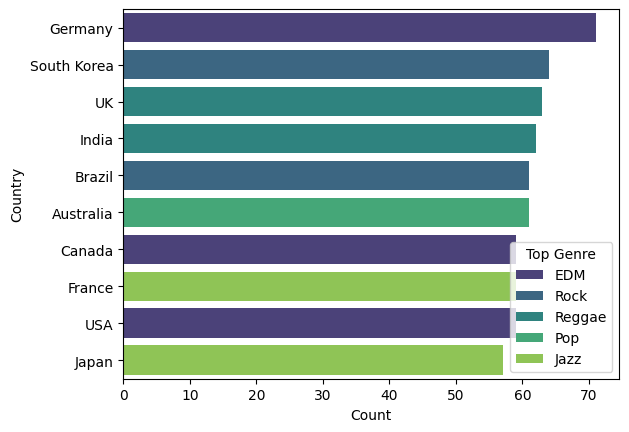

In [13]:
##
## group by Country and Top Genre
#top_genre_by_country = df.groupby(['Country', 'Top Genre']).size().reset_index(name = "Count").sort_values(['Country', 'Top Genre'], ascending = ['True','False'])

top_genre_by_country = (
    df.groupby(['Country', 'Top Genre'])
  .size()
  .reset_index(name = "Count")
  .sort_values(['Country', 'Count'], ascending = [True,False])
)


top_genre_by_country

top_genre = top_genre_by_country.groupby('Country').first().reset_index().sort_values(by='Count', ascending=False)
top_genre

sns.barplot(
    data= top_genre,
    x='Count',
    y='Country',
    hue='Top Genre',
    palette='viridis'
)

In [14]:
df.head()

,User_ID,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%),Age Group
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74,31-50
1,U1001,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25,18-30
2,U1002,49,Germany,Deezer,Pop,363,368,Post Malone,Premium,Afternoon,47.19,67.38,31-50
3,U1003,55,Australia,YouTube,Reggae,348,349,Dua Lipa,Premium,Morning,31.27,76.51,51-70
4,U1004,13,Germany,Amazon Music,Reggae,30,328,Adele,Free,Night,30.68,43.41,<18


In [15]:
pivot_counts = pd.pivot_table(
    df,
    index='Country',
    columns='Top Genre',
    values='User_ID',
    aggfunc='count',
    fill_value=0
)

pivot_counts

Top Genre,Classical,Country,EDM,Hip-Hop,Jazz,Metal,Pop,R&B,Reggae,Rock
Country,,,,,,,,,,
Australia,47,49,53,55,60,43,61,48,55,55
Brazil,59,53,48,39,45,44,56,57,46,61
Canada,37,51,59,51,57,38,56,54,55,49
France,42,47,50,52,59,51,35,51,55,51
Germany,45,45,71,44,44,56,37,50,37,42
India,55,49,42,54,52,45,40,45,62,46
Japan,45,55,48,48,57,51,55,41,49,42
South Korea,48,47,56,61,51,52,34,52,51,64
UK,49,42,42,47,56,58,45,59,63,55


In [16]:
top_genre_per_country = pd.DataFrame({
    'Country': pivot_counts.index,
    'Top Genre': pivot_counts.idxmax(axis=1).values,
    'Count': pivot_counts.max(axis=1).values
}).sort_values(by='Count', ascending=True)

top_genre_per_country

,Country,Top Genre,Count
6,Japan,Jazz,57
3,France,Jazz,59
2,Canada,EDM,59
9,USA,EDM,59
0,Australia,Pop,61
1,Brazil,Rock,61
5,India,Reggae,62
8,UK,Reggae,63
7,South Korea,Rock,64
4,Germany,EDM,71
